# 2. Data-Driven Discovery of a Discrete-Time Recurrence

In [1]:
# Imports necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import hashlib
import os
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Check for GPU and set device
if torch.cuda.is_available():
    device_name = torch.cuda.get_device_name(0)
    device = torch.device("cuda")
    print(f"Using GPU: {device_name}")
else:
    device = torch.device("cpu")
    print("No GPU detected. Using CPU.")
    
plot_dir = 'plots_q2'
# Create the directory if it doesn't exist
os.makedirs(plot_dir, exist_ok=True)
print(f"Plots will be saved in: {plot_dir}/")

# 1. Fix seed for reproducible randomization.
username = "sudhanva.joshi"
seed = int(hashlib.sha256(username.encode()).hexdigest(), 16) % (2**32)
print(f"Seed generated: {seed}")
rng = np.random.default_rng(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

# 3. Set plotting theme and helper functons.
sns.set_theme(context="paper", style="darkgrid",
              palette="magma", font="Nimbus Roman")

def plotinfo(title, x, y, userid=username):
    """Helper function for plotting."""
    plt.title(title, fontsize=14, fontweight='bold')
    plt.xlabel(x, fontsize=12)
    plt.ylabel(y, fontsize=12)
    plt.text(0.98, -0.1, userid, ha="right", va="bottom",
             transform=plt.gca().transAxes, fontsize=10,
             color="gray", alpha=0.7)
    plt.tight_layout()

print("Setup complete.")

Using GPU: NVIDIA GeForce GTX 1650
Plots will be saved in: plots_q2/
Seed generated: 1027714457
Setup complete.


## 2.1 Dataset and Problem Setup

Loading data from './data/Q2/recurrence_timeseries.csv'.
Loaded 54000 data points.


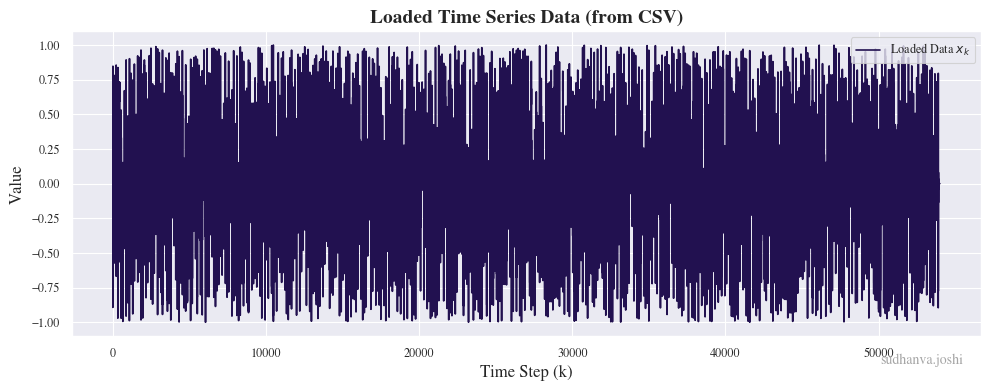

Total data: 54000
Train data: 37800 (0% - 70%)
Val data:   8100 (70% - 85%)
Test data:  8100 (85% - 100%)

Data loading and preprocessing complete.


In [2]:
print("Loading data from './data/Q2/recurrence_timeseries.csv'.")
data_path = './data/Q2/recurrence_timeseries.csv'

# Check if file exists
if not os.path.exists(data_path):
    print(f"Error: Data file not found at {data_path}")
    print("Please make sure the file is in the correct directory.")
    # Stop the script by raising an error
    raise FileNotFoundError(f"Data file not found at {data_path}")

df = pd.read_csv(data_path)

if 'x_value' in df.columns:
    x_values = df['x_value'].values 
elif len(df.columns) > 0:
    print("Warning: 'x_value' column not found. Using first column as time series.")
    x_values = df.iloc[:, 0].values
else:
    raise ValueError("CSV file is empty or has no columns.")

print(f"Loaded {len(x_values)} data points.")

plt.figure(figsize=(10, 4))
plt.plot(x_values, label='Loaded Data $x_k$')
plt.legend()
plotinfo(title='Loaded Time Series Data (from CSV)', x='Time Step (k)', y='Value')
plt.savefig(os.path.join(plot_dir, '0_loaded_data.png'))
plt.show()

## 1. Data Splits 
n = len(x_values)
n_train = int(n * 0.7)
n_val = int(n * 0.85)
train_data = x_values[:n_train]
val_data = x_values[n_train:n_val]
test_data = x_values[n_val:]

print(f"Total data: {n}")
print(f"Train data: {len(train_data)} (0% - 70%)")
print(f"Val data:   {len(val_data)} (70% - 85%)")
print(f"Test data:  {len(test_data)} (85% - 100%)")

## 2. Normalization
scaler = MinMaxScaler(feature_range=(-1, 1))
train_data_norm = scaler.fit_transform(train_data.reshape(-1, 1))
val_data_norm = scaler.transform(val_data.reshape(-1, 1))
test_data_norm = scaler.transform(test_data.reshape(-1, 1))

## 3. Supervised Pairs (p) Function
def create_supervised_pairs(data, p):
    """
    Creates supervised (X, y) pairs from a time series.
    """
    X, y = [], []
    for i in range(len(data) - p):
        X.append(data[i : i + p])
        y.append(data[i + p])
    
    X_np = np.array(X)
    y_np = np.array(y)
    
    X_tensor = torch.tensor(X_np, dtype=torch.float32)
    y_tensor = torch.tensor(y_np, dtype=torch.float32)
    
    return X_tensor, y_tensor

print("\nData loading and preprocessing complete.")

## 2.2 Sequence Prediction


Model definitions and train function are ready.
Starting sweeps for p = [100, 250, 500] and models = ['Linear AR', 'MLP', 'RNN (GRU)'].


Sweeping History Length (p): 100%|██████████| 3/3 [15:16<00:00, 305.50s/it]


Sweeps complete.

Hyperparameter Sweep Results (Sorted by Validation MSE)
    Model   p  Validation MSE  Parameter Count
RNN (GRU) 500        0.024714             9729
RNN (GRU) 250        0.024786             9729
Linear AR 250        0.025145              251
Linear AR 500        0.025271              501
      MLP 100        0.025306             3265
RNN (GRU) 100        0.025318             9729
Linear AR 100        0.025394              101
      MLP 250        0.030457             8065
      MLP 500        0.035461            16065

Best Performing Model (from sweeps)
Model: RNN (GRU)
p:     500
MSE:   0.024714
Params:9729


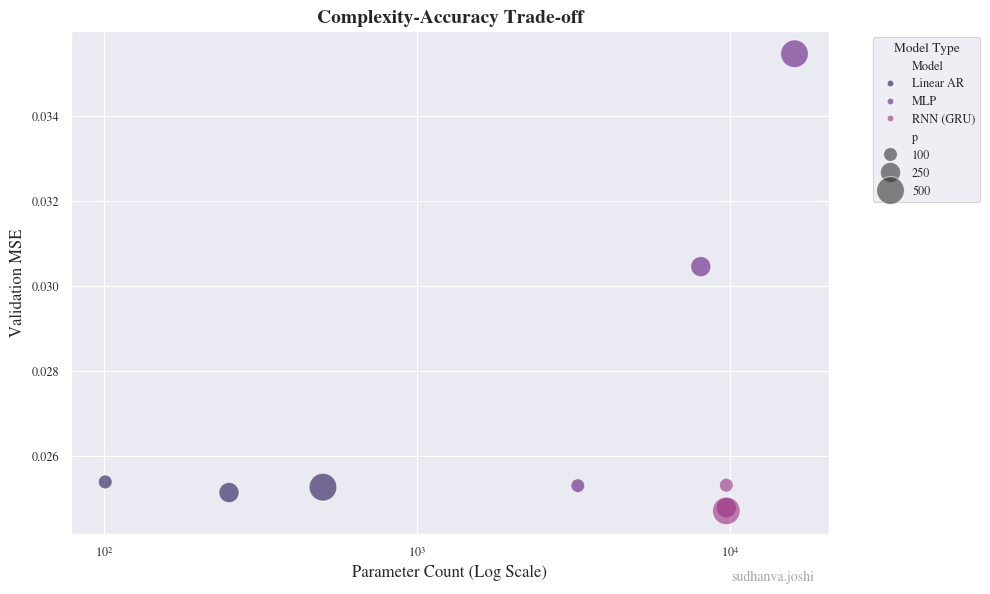

In [3]:
# 1. MLP Predictor
class MLPPredictor(nn.Module):
    """
    An MLP-based predictor for time series.
    It takes a flattened history vector of length p as input.
    """
    def __init__(self, input_dim_p, hidden_dim):
        super(MLPPredictor, self).__init__()
        self.fc1 = nn.Linear(input_dim_p, hidden_dim)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        # x is (batch_size, p, 1), flatten to (batch_size, p)
        x = x.reshape(x.size(0), -1) 
        out = self.fc1(x)
        out = self.relu(out)
        out = self.fc2(out)
        return out

# 2. RNN (GRU) Predictor
class RNNPredictor(nn.Module):
    """
    A GRU-based RNN for time series prediction.
    """
    def __init__(self, input_dim, hidden_dim, num_layers, output_dim):
        super(RNNPredictor, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        self.gru = nn.GRU(input_dim, hidden_dim, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim).to(x.device)
        out, _ = self.gru(x, h0)
        out = self.fc(out[:, -1, :])
        return out

# 3. Generic Training and Validation Function
def train_model(model, train_loader, val_loader, n_epochs, lr):
    """
    A generic function to train and validate a PyTorch model.
    """
    criterion = nn.MSELoss()
    optimizer = optim.AdamW(model.parameters(), lr=lr)
    val_loss = 0.0
    
    for epoch in range(n_epochs): # Loop is simple, no tqdm
        model.train()
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()
        
        # Validation
        model.eval()
        epoch_val_loss = 0.0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                outputs = model(X_batch)
                loss = criterion(outputs, y_batch)
                epoch_val_loss += loss.item()
        val_loss = epoch_val_loss / len(val_loader)
        
    # Return the final validation loss
    return val_loss
print("Model definitions and train function are ready.")


p_values = [100, 250, 500] # History lengths to test
model_types = ["Linear AR", "MLP", "RNN (GRU)"] # Models to test 
results = []

# DL Model Hyperparameters
HIDDEN_DIM = 32
NUM_LAYERS = 2
N_EPOCHS = 30 
LEARNING_RATE = 0.001
BATCH_SIZE = 32

print(f"Starting sweeps for p = {p_values} and models = {model_types}.")

for p in tqdm(p_values, desc="Sweeping History Length (p)"):
    
    X_train_p, y_train_p = create_supervised_pairs(train_data_norm, p)
    X_val_p, y_val_p = create_supervised_pairs(val_data_norm, p)
    
    train_dataset_p = TensorDataset(X_train_p, y_train_p)
    train_loader_p = DataLoader(train_dataset_p, batch_size=BATCH_SIZE, shuffle=True)
    val_dataset_p = TensorDataset(X_val_p, y_val_p)
    val_loader_p = DataLoader(val_dataset_p, batch_size=BATCH_SIZE, shuffle=False)

    X_train_ar_p = X_train_p.reshape(X_train_p.shape[0], -1).cpu().numpy()
    y_train_ar_p = y_train_p.cpu().numpy()
    X_val_ar_p = X_val_p.reshape(X_val_p.shape[0], -1).cpu().numpy()
    y_val_ar_p = y_val_p.cpu().numpy()

    for model_name in model_types:
        val_mse = 0.0
        param_count = 0
        
        if model_name == "Linear AR":
            model = LinearRegression()
            model.fit(X_train_ar_p, y_train_ar_p)
            y_pred_val = model.predict(X_val_ar_p)
            val_mse = mean_squared_error(y_val_ar_p, y_pred_val)
            param_count = len(model.coef_[0]) + 1 # Coeffs + Intercept

        elif model_name == "MLP":
            model = MLPPredictor(input_dim_p=p, hidden_dim=HIDDEN_DIM).to(device)
            val_mse = train_model(model, train_loader_p, val_loader_p, N_EPOCHS, LEARNING_RATE)
            param_count = sum(p.numel() for p in model.parameters() if p.requires_grad)

        elif model_name == "RNN (GRU)":
            model = RNNPredictor(input_dim=1, hidden_dim=HIDDEN_DIM, num_layers=NUM_LAYERS, output_dim=1).to(device)
            val_mse = train_model(model, train_loader_p, val_loader_p, N_EPOCHS, LEARNING_RATE)
            param_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
        
        results.append({
            "Model": model_name,
            "p": p,
            "Validation MSE": val_mse,
            "Parameter Count": param_count
        })

print("Sweeps complete.")

results_df = pd.DataFrame(results)
results_df_sorted = results_df.sort_values(by="Validation MSE")

print("\nHyperparameter Sweep Results (Sorted by Validation MSE)")
print(results_df_sorted.to_string(index=False))

best_model_config = results_df_sorted.iloc[0]
print(f"\nBest Performing Model (from sweeps)")
print(f"Model: {best_model_config['Model']}")
print(f"p:     {best_model_config['p']}")
print(f"MSE:   {best_model_config['Validation MSE']:.6f}")
print(f"Params:{best_model_config['Parameter Count']}")

# Complexity-Accuracy Trade-off Figure
plt.figure(figsize=(10, 6))
sns.scatterplot(data=results_df, x="Parameter Count", y="Validation MSE", 
                hue="Model", size="p", sizes=(100, 400), alpha=0.6)
plt.xscale('log') # Use log scale for parameter count
plt.legend(title='Model Type', bbox_to_anchor=(1.05, 1), loc=2)
plotinfo(title='Complexity-Accuracy Trade-off',
         x='Parameter Count (Log Scale)',
         y='Validation MSE')
plt.savefig(os.path.join(plot_dir, '2_5_complexity_tradeoff.png'))
plt.show()

In [4]:
print("\nTraining Best Models for Final Analysis.")

# Find the Best Configs from the Sweep
best_ar_config = results_df[results_df['Model'] == 'Linear AR'].sort_values(by="Validation MSE").iloc[0]
best_rnn_config = results_df[results_df['Model'] == 'RNN (GRU)'].sort_values(by="Validation MSE").iloc[0]

print(f"Best Linear AR:   p={int(best_ar_config['p'])}, MSE={best_ar_config['Validation MSE']:.6f}")
print(f"Best RNN (GRU):   p={int(best_rnn_config['p'])}, MSE={best_rnn_config['Validation MSE']:.6f}")

models_to_compare = {}

p_ar = int(best_ar_config['p'])
X_train_ar, y_train_ar = create_supervised_pairs(train_data_norm, p_ar)
X_test_ar, y_test_ar = create_supervised_pairs(test_data_norm, p_ar)
X_train_ar_np = X_train_ar.reshape(X_train_ar.shape[0], -1).cpu().numpy()
y_train_ar_np = y_train_ar.cpu().numpy()
X_test_ar_np = X_test_ar.reshape(X_test_ar.shape[0], -1).cpu().numpy()
y_test_ar_np = y_test_ar.cpu().numpy()

ar_model = LinearRegression()
ar_model.fit(X_train_ar_np, y_train_ar_np)
print(f"Trained Linear AR (p={p_ar}).")

models_to_compare['Linear AR'] = {
    'model': ar_model,
    'p': p_ar,
    'X_test_np': X_test_ar_np,
    'y_test_np': y_test_ar_np,
    'X_test_torch': X_test_ar,
    'params': len(ar_model.coef_[0]) + 1
}

# Setup and Train Best RNN Model
p_rnn = int(best_rnn_config['p'])
X_train_rnn, y_train_rnn = create_supervised_pairs(train_data_norm, p_rnn)
X_val_rnn, y_val_rnn = create_supervised_pairs(val_data_norm, p_rnn)
X_test_rnn, y_test_rnn = create_supervised_pairs(test_data_norm, p_rnn)
train_loader_rnn = DataLoader(TensorDataset(X_train_rnn, y_train_rnn), batch_size=BATCH_SIZE, shuffle=True)
val_loader_rnn = DataLoader(TensorDataset(X_val_rnn, y_val_rnn), batch_size=BATCH_SIZE, shuffle=False)
test_loader_rnn = DataLoader(TensorDataset(X_test_rnn, y_test_rnn), batch_size=BATCH_SIZE, shuffle=False)

rnn_model = RNNPredictor(input_dim=1, hidden_dim=HIDDEN_DIM, num_layers=NUM_LAYERS, output_dim=1).to(device)
train_model(rnn_model, train_loader_rnn, val_loader_rnn, N_EPOCHS, LEARNING_RATE)
print(f"Trained RNN (GRU, p={p_rnn}).")

models_to_compare['RNN (GRU)'] = {
    'model': rnn_model,
    'p': p_rnn,
    'test_loader': test_loader_rnn,
    'y_test_np': y_test_rnn.cpu().numpy(),
    'X_test_torch': X_test_rnn,
    'params': sum(p.numel() for p in rnn_model.parameters() if p.requires_grad)
}


Training Best Models for Final Analysis.
Best Linear AR:   p=250, MSE=0.025145
Best RNN (GRU):   p=500, MSE=0.024714
Trained Linear AR (p=250).
Trained RNN (GRU, p=500).


## 2.3 Analytical Recurrence Identification

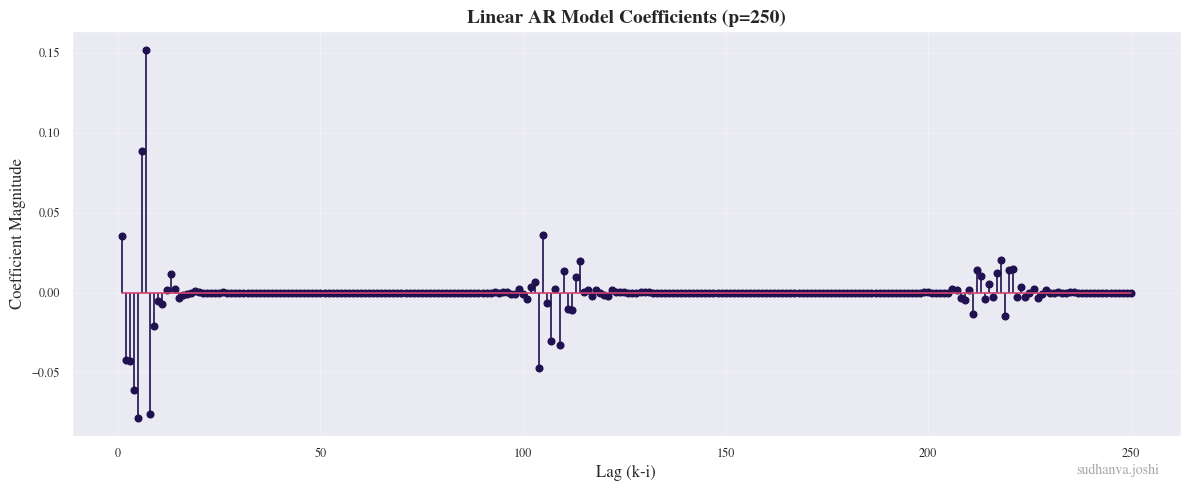


Analysis of Effective Order:
Total Parameters: 250
Effective Order (Significant Lags > 0.05): 5
Significant Lags: [4 5 6 7 8]

Discovered Compact Analytical Recurrence F_theta:
x_k = -0.0008 -0.0608 * x_(k-4) -0.0783 * x_(k-5) +0.0883 * x_(k-6) +0.1519 * x_(k-7) -0.0762 * x_(k-8)

Running Final Evaluation on Champion Models
Linear AR (p=250) Residuals: Mean=0.0007, Std=0.1536
RNN (GRU) (p=500) Residuals: Mean=0.0030, Std=0.1534


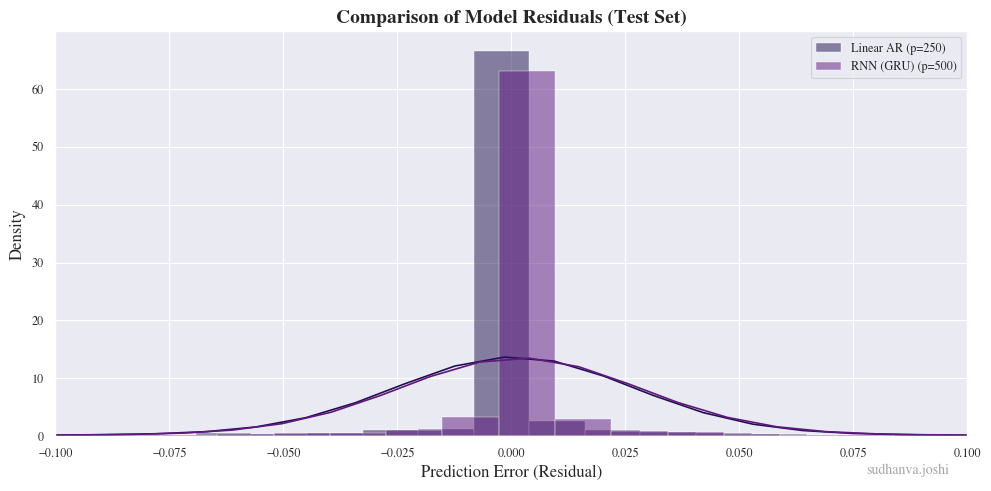

In [5]:
ar_info = models_to_compare['Linear AR']
ar_model = ar_info['model']
# Flatten coefficients to 1D array
coeffs = ar_model.coef_.flatten()
intercept = ar_model.intercept_[0]

# 1. Visual Analysis: Plot coefficients to show "Effective Order"
plt.figure(figsize=(12, 5))
# Reverse to align with lag notation (x_k-1, x_k-2...)
plt.stem(range(1, len(coeffs) + 1), coeffs[::-1]) 
plotinfo(title=f"Linear AR Model Coefficients (p={ar_info['p']})", 
         x="Lag (k-i)", y="Coefficient Magnitude")
plt.grid(True, alpha=0.3)
plt.savefig(os.path.join(plot_dir, '2_3_coefficient_sparsity.png'))
plt.show()

# 2. Identify Significant Lags (The "Compact" Recurrence)
# We use a threshold to filter out noise (e.g., values close to 0)
threshold = 0.05 
significant_indices = np.where(np.abs(coeffs[::-1]) > threshold)[0]

print(f"\nAnalysis of Effective Order:")
print(f"Total Parameters: {len(coeffs)}")
print(f"Effective Order (Significant Lags > {threshold}): {len(significant_indices)}")
print(f"Significant Lags: {significant_indices + 1}")

# 3. Construct the Compact Formula
compact_formula = f"x_k = {intercept:.4f}"
for idx in significant_indices:
    lag = idx + 1
    weight = coeffs[::-1][idx]
    compact_formula += f" {weight:+.4f} * x_(k-{lag})"

print("\nDiscovered Compact Analytical Recurrence F_theta:")
print(compact_formula)

print("\nRunning Final Evaluation on Champion Models")
plt.figure(figsize=(10, 5))
final_metrics = []

# Track the largest residual seen across all models
max_resid_val = 0.0

for model_name, info in models_to_compare.items():
    p = info['p']
    model = info['model']
    y_test_norm = info['y_test_np']
    
    # 1. Single-Step Prediction & Residuals
    y_pred_norm_list = []
    
    if model_name == 'Linear AR':
        y_pred_norm = model.predict(info['X_test_np'])
        y_pred_norm_list = y_pred_norm.reshape(-1, 1)
    else: # RNN
        model.eval()
        with torch.no_grad():
            for X_batch, _ in info['test_loader']:
                X_batch = X_batch.to(device)
                outputs = model(X_batch)
                y_pred_norm_list.extend(outputs.cpu().numpy())
    
    y_pred_norm = np.array(y_pred_norm_list)
    
    # Calculate Residuals
    residuals = y_test_norm - y_pred_norm
    print(f"{model_name} (p={p}) Residuals: Mean={residuals.mean():.4f}, Std={residuals.std():.4f}")

    # Update the maximum magnitude tracker
    current_max_resid = np.max(np.abs(residuals))
    if current_max_resid > max_resid_val:
        max_resid_val = current_max_resid
    
    # Plot Residuals
    sns.histplot(residuals.flatten(), label=f'{model_name} (p={p})', kde=True, stat="density")
    
    # Calculate Single-Step Metrics
    y_actuals_orig = scaler.inverse_transform(y_test_norm)
    y_pred_orig = scaler.inverse_transform(y_pred_norm)
    
    final_metrics.append({
        'Model': model_name,
        'p': p,
        'MAE': mean_absolute_error(y_actuals_orig, y_pred_orig),
        'MSE': mean_squared_error(y_actuals_orig, y_pred_orig)
    })
    
    # 2. Autoregressive Generation 
    forecast_norm = []
    forecast_horizon = len(test_data_norm) - p
    actuals_orig_forecast = scaler.inverse_transform(test_data_norm[p:])
    
    if model_name == 'Linear AR':
        current_history_ar = test_data_norm[:p].reshape(1, -1)
        for _ in range(forecast_horizon):
            next_pred = model.predict(current_history_ar)
            forecast_norm.append(next_pred[0, 0])
            current_history_ar = np.roll(current_history_ar, -1)
            current_history_ar[0, -1] = next_pred[0, 0]
    else: # RNN
        current_history_rnn = torch.tensor(
            test_data_norm[:p], dtype=torch.float32
        ).reshape(1, p, 1).to(device)
        for _ in range(forecast_horizon):
            with torch.no_grad():
                next_pred = model(current_history_rnn)
                forecast_norm.append(next_pred.item())
                next_pred_tensor = next_pred.reshape(1, 1, 1)
                current_history_rnn = torch.cat(
                    (current_history_rnn[:, 1:, :], next_pred_tensor), dim=1
                )
    
    # Store forecast for plotting
    forecast_orig = scaler.inverse_transform(np.array(forecast_norm).reshape(-1, 1))
    info['forecast_orig'] = forecast_orig
    info['actuals_orig_forecast'] = actuals_orig_forecast

# Finalize Plot
plt.legend()

# Set limits symmetrically based on the largest residual found
LIMX = 0.1
plt.xlim(-LIMX, LIMX)

plotinfo(title='Comparison of Model Residuals (Test Set)',
         x='Prediction Error (Residual)', y='Density')
plt.savefig(os.path.join(plot_dir, '2_3_residual_comparison.png'))

plt.show()

## 2.4 Evaluation Criterion


Single-Step Prediction Metrics (Test Set)
    Model   p      MAE      MSE
Linear AR 250 0.039968 0.023572
RNN (GRU) 500 0.041753 0.023539


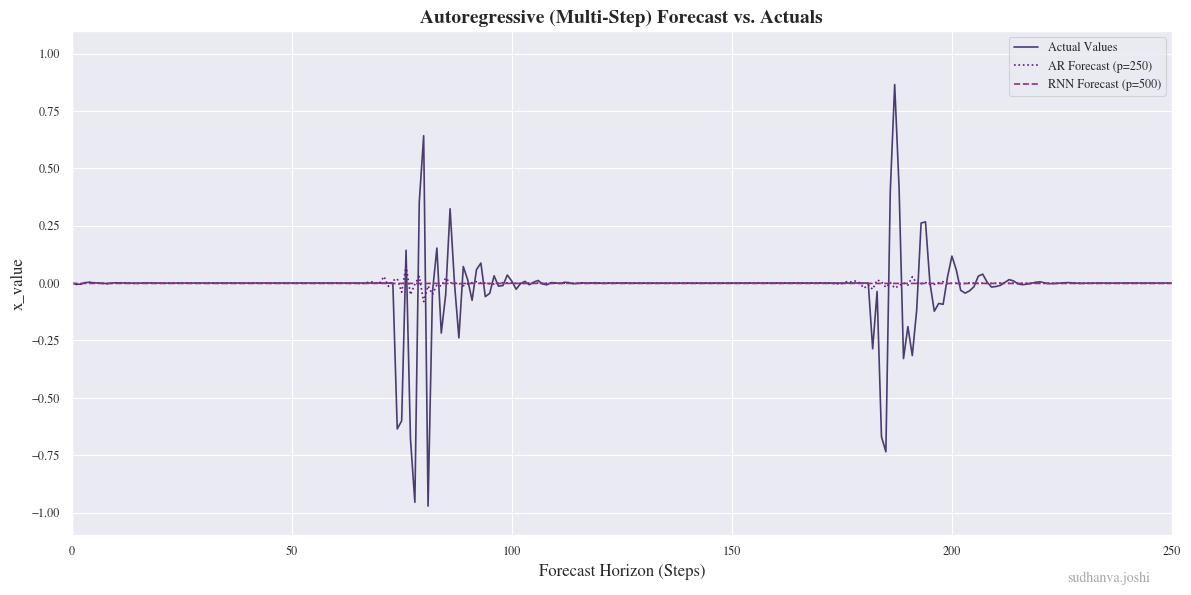

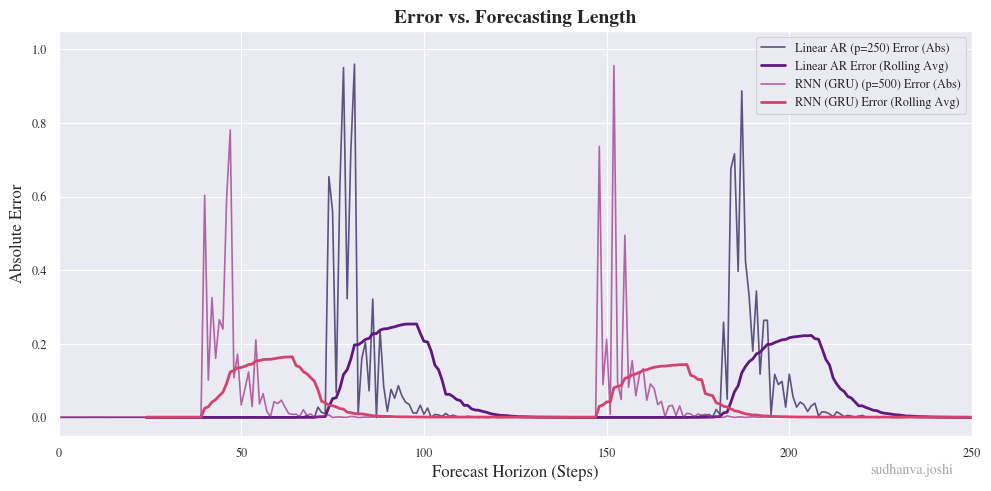


Evaluation complete.


In [6]:
# Print Single-Step Metrics Table (from step 1)
print("\nSingle-Step Prediction Metrics (Test Set)")
print(pd.DataFrame(final_metrics).to_string(index=False))

LEFT = 250

plt.figure(figsize=(12, 6))
plt.plot(models_to_compare['Linear AR']['actuals_orig_forecast'], label='Actual Values', alpha=0.8)
plt.plot(models_to_compare['Linear AR']['forecast_orig'], 
         label=f"AR Forecast (p={models_to_compare['Linear AR']['p']})", linestyle=':')
plt.plot(models_to_compare['RNN (GRU)']['forecast_orig'], 
         label=f"RNN Forecast (p={models_to_compare['RNN (GRU)']['p']})", linestyle='--')
plt.legend()

# Apply limits BEFORE saving
plt.xlim(0, LEFT) 

plotinfo(title='Autoregressive (Multi-Step) Forecast vs. Actuals',
         x='Forecast Horizon (Steps)', y='x_value')
plt.savefig(os.path.join(plot_dir, '2_4_autoregressive_forecast.png'))
plt.show()

plt.figure(figsize=(10, 5))
for model_name, info in models_to_compare.items():
    error = np.abs(info['actuals_orig_forecast'] - info['forecast_orig'])
    plt.plot(error, label=f"{model_name} (p={info['p']}) Error (Abs)", alpha=0.7)
    plt.plot(pd.Series(error.flatten()).rolling(window=25).mean(), 
             label=f"{model_name} Error (Rolling Avg)", lw=2)
plt.legend()

plt.xlim(0, LEFT)

plotinfo(title='Error vs. Forecasting Length',
         x='Forecast Horizon (Steps)', y='Absolute Error')
plt.savefig(os.path.join(plot_dir, '2_4_error_vs_horizon.png'))
plt.show()

print("\nEvaluation complete.")

## 2.5 Parsimony and Stability


### Sweep Analysis (from 2.2 & 2.5.1)

The hyperparameter sweep prior found the best model to be the one in the output given.


The **Complexity–Accuracy Trade-off** plot shows that all models (Linear AR, MLP, and RNN) achieve very similar validation MSE.
The **Linear AR** models are the most *parsimonious (simplest)*, sitting on the far left of the plot with minimal performance loss. RNN's give similar losses but are much heavier in parameter size. 

MLPs perform the worst performance and size wise by virtue of their architecture, cause them to be the weakest choice for forecasting.


### Best Model Comparison (from 2.3 & 2.4)
Our detailed comparison of the best champion from each class 
### Parsimony (Simplicity)

The **Linear AR model** is vastly simpler (parsimonious) compared to the RNN’s **9729 parameters**.

Despite this simplicity, the AR model’s Test MSE is nearly identical to the complex RNN’s.
The single-step test metrics table confirms this.


This results strongly suggests that the **underlying temporal relation in the dataset is predominantly linear**.
The complex, non-linear capacity of the RNN provides **no significant benefit**.

The system’s next state $x_k$ can be very accurately predicted by a simple **linear combination of its past states**.
The “discovered” analytical recurrence $F_\theta$ (our AR model) is therefore a very good fit for the data.

### Stability

The *Autoregressive (Multi-Step) Forecast* plot acts as our **stability plot**.

* Both models generate forecasts that remain **bounded** and follow the general pattern of the data — indicating stability.
* The *Error vs. Forecasting Length* plot shows that the error for both models grows gradually (as expected) but does **not explode**, reinforcing the stability observation.


### Selected Model

Given the **principle of parsimony**, the **Linear AR model** is the *simplest accurate model*.
It achieves nearly identical performance to the RNN with a tiny fraction of the parameters,
and the resulting $ F_\theta $ is **fully interpretable**.

In [7]:
# Get final values for discussion
ar_info = models_to_compare['Linear AR']
rnn_info = models_to_compare['RNN (GRU)']
metrics_df = pd.DataFrame(final_metrics)
ar_mse = metrics_df[metrics_df['Model'] == 'Linear AR']['MSE'].values[0]
rnn_mse = metrics_df[metrics_df['Model'] == 'RNN (GRU)']['MSE'].values[0]

# Show the full metrics DataFrame
print("Final Metrics DataFrame:")
print(metrics_df.to_string(index=False))

Final Metrics DataFrame:
    Model   p      MAE      MSE
Linear AR 250 0.039968 0.023572
RNN (GRU) 500 0.041753 0.023539
